PyTorch: 2.14.1+cu130 | urządzenie: cuda


Saving images.jpg to images.jpg
Rozmiar tensora: (1, 1, 224, 224)
Typ danych: torch.float32


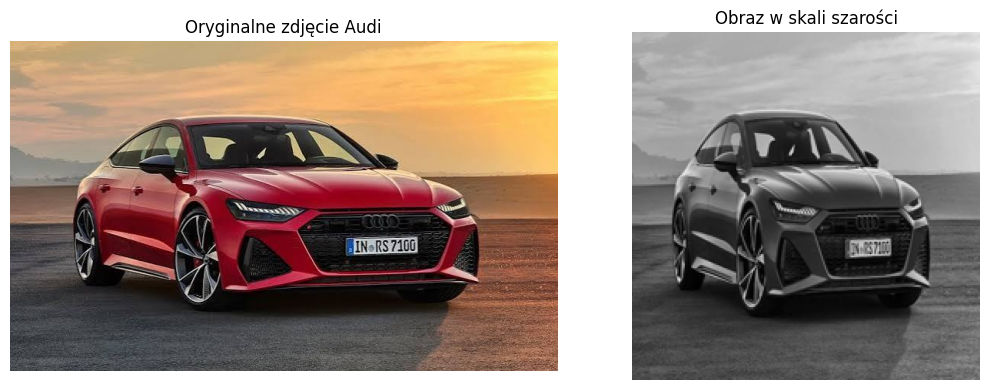

In [1]:
# import bibliotek
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

# wczytanie własnego zdjęcia
uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert("RGB")
pil = original.resize((224, 224))
pil_gray = pil.convert("L")

# obraz jako tensor [1, 1, H, W]
gray = transforms.ToTensor()(pil_gray).unsqueeze(0)

print("Rozmiar tensora:", tuple(gray.shape))
print("Typ danych:", gray.dtype)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(original)
axes[0].set_title("Oryginalne zdjęcie Audi")
axes[0].axis("off")

axes[1].imshow(pil_gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Obraz w skali szarości")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [2]:
# wzór na wymiary wyjścia
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1

IN = 32

configs = [
    dict(k=3, s=1, p=1, d=1),
    dict(k=3, s=2, p=1, d=1),
    dict(k=5, s=1, p=2, d=1),
    dict(k=3, s=1, p=2, d=2),
    dict(k=7, s=2, p=3, d=1)
]

print(f"Wejście: {IN} x {IN}")
print(f"{'k':>3} {'s':>3} {'p':>3} {'d':>3} | {'wzór':>7} {'Conv2d':>8}")

x = torch.randn(1, 3, IN, IN)

for c in configs:
    conv = nn.Conv2d(
        3, 8,
        kernel_size=c["k"],
        stride=c["s"],
        padding=c["p"],
        dilation=c["d"]
    )

    real = conv(x).shape[-1]
    formula = out_dim(IN, **c)

    print(
        f"{c['k']:>3} {c['s']:>3} {c['p']:>3} {c['d']:>3} | "
        f"{formula:>7} {real:>8}"
    )


Wejście: 32 x 32
  k   s   p   d |    wzór   Conv2d
  3   1   1   1 |      32       32
  3   2   1   1 |      16       16
  5   1   2   1 |      32       32
  3   1   2   2 |      32       32
  7   2   3   1 |      16       16


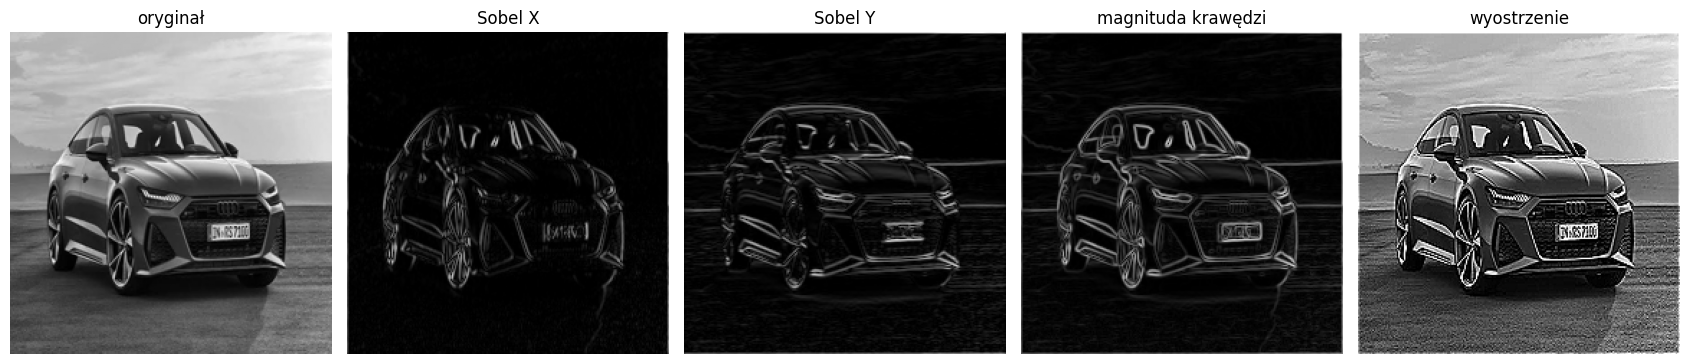

In [4]:
# ręczne jądra splotowe
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(
        1, 1, *np.array(t).shape
    )

sobel_x = kernel([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = kernel([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

sharpen = kernel([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# zastosowanie F.conv2d
gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)

edges = (gx**2 + gy**2).sqrt()
sharp = F.conv2d(gray, sharpen, padding=1).clamp(0, 1)

results = {
    "oryginał": gray,
    "Sobel X": gx.abs(),
    "Sobel Y": gy.abs(),
    "magnituda krawędzi": edges,
    "wyostrzenie": sharp
}

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, (name, out) in zip(axes, results.items()):
    ax.imshow(out[0, 0].numpy(), cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()


stride=1, padding=1, dilation=1 -> (224, 224)
stride=2, padding=1, dilation=1 -> (112, 112)
stride=1, padding=0, dilation=1 -> (222, 222)
stride=1, padding=2, dilation=2 -> (224, 224)


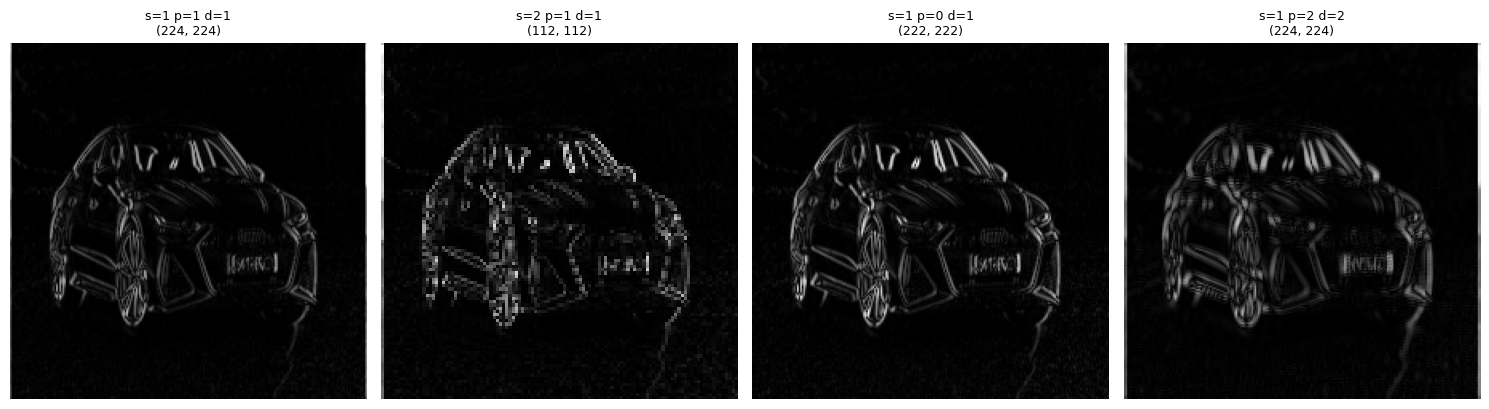

In [5]:
# wpływ stride, padding i dilation
settings = [
    dict(stride=1, padding=1, dilation=1),
    dict(stride=2, padding=1, dilation=1),
    dict(stride=1, padding=0, dilation=1),
    dict(stride=1, padding=2, dilation=2)
]

outputs = []

for s in settings:
    out = F.conv2d(gray, sobel_x, **s)
    outputs.append(out)
    print(
        f"stride={s['stride']}, "
        f"padding={s['padding']}, "
        f"dilation={s['dilation']} "
        f"-> {tuple(out.shape[-2:])}"
    )

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, s, out in zip(axes, settings, outputs):
    ax.imshow(out[0, 0].abs().numpy(), cmap="gray")
    ax.set_title(
        f"s={s['stride']} p={s['padding']} d={s['dilation']}\n"
        f"{tuple(out.shape[-2:])}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 149MB/s]


Wejście sieci: (1, 3, 224, 224)
Mapy cech: (64, 112, 112)


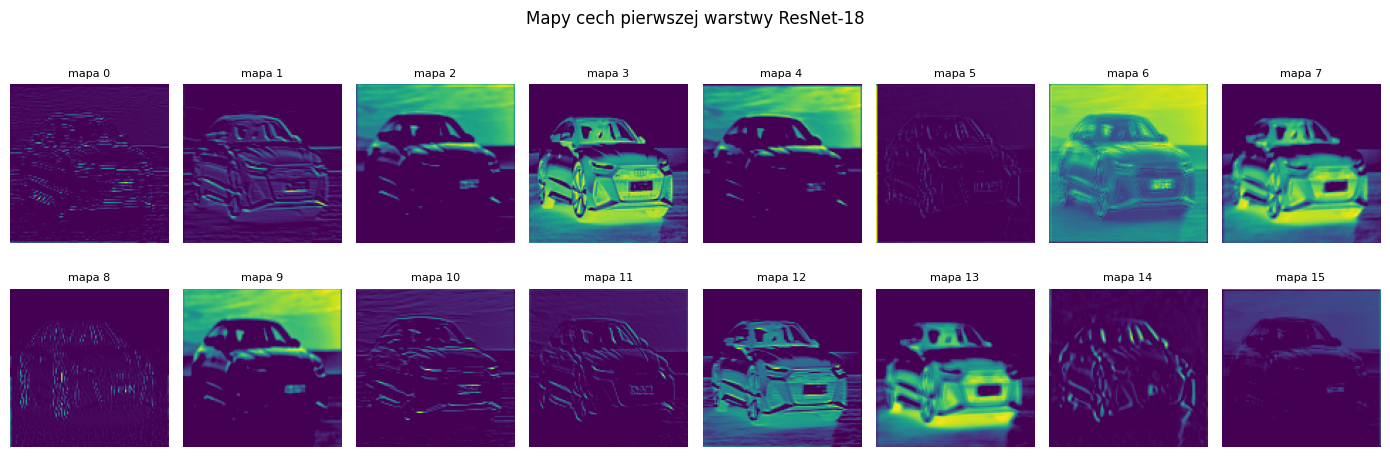

In [6]:
# filtry i mapy cech wyuczonej sieci
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

preprocess = weights.transforms()

# ta sama skala szarości w trzech kanałach
gray_rgb = pil_gray.convert("RGB")

x = preprocess(gray_rgb).unsqueeze(0).to(device)

print("Wejście sieci:", tuple(x.shape))

# mapy pierwszej warstwy splotowej
with torch.no_grad():
    maps = torch.relu(model.conv1(x))[0].cpu()

print("Mapy cech:", tuple(maps.shape))

fig, axes = plt.subplots(2, 8, figsize=(14, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(maps[i].numpy(), cmap="viridis")
    ax.set_title(f"mapa {i}", fontsize=8)
    ax.axis("off")

plt.suptitle("Mapy cech pierwszej warstwy ResNet-18")
plt.tight_layout()
plt.show()


Oryginał: (1, 1, 224, 224)
Box 3x3: (1, 1, 224, 224)
Box 5x5: (1, 1, 224, 224)
Gaussian 5x5: (1, 1, 224, 224)


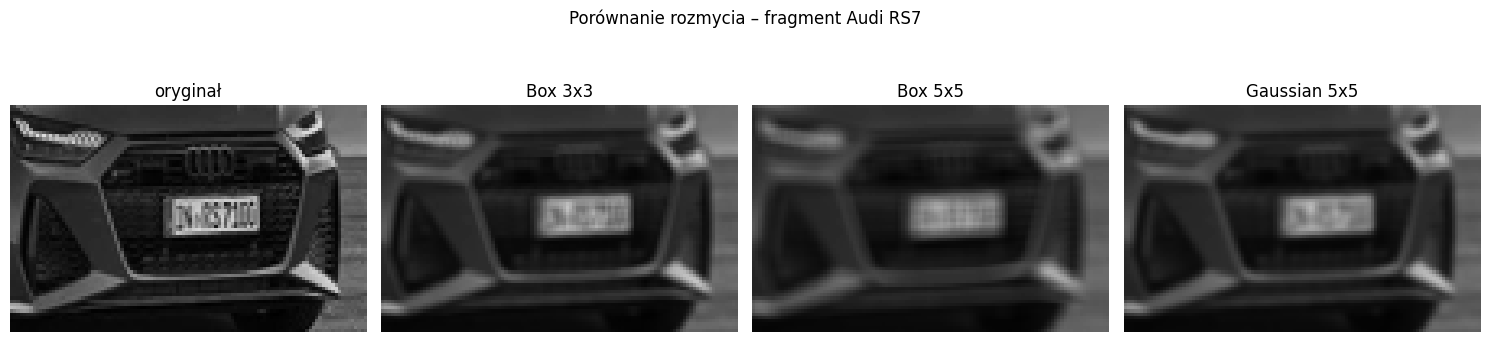

In [7]:
# porównanie filtrów rozmywających

box3 = torch.ones(1, 1, 3, 3) / 9
box5 = torch.ones(1, 1, 5, 5) / 25

v = torch.tensor([1, 4, 6, 4, 1], dtype=torch.float32)
gaussian5 = torch.outer(v, v).view(1, 1, 5, 5) / 256

# stride=1, dilation=1
blur_box3 = F.conv2d(
    gray, box3, stride=1, padding=1, dilation=1
)

blur_box5 = F.conv2d(
    gray, box5, stride=1, padding=2, dilation=1
)

blur_gauss5 = F.conv2d(
    gray, gaussian5, stride=1, padding=2, dilation=1
)

print("Oryginał:", tuple(gray.shape))
print("Box 3x3:", tuple(blur_box3.shape))
print("Box 5x5:", tuple(blur_box5.shape))
print("Gaussian 5x5:", tuple(blur_gauss5.shape))

# ten sam fragment zdjęcia – przód Audi
y0, y1 = 105, 175
x0, x1 = 90, 200

comparison = {
    "oryginał": gray,
    "Box 3x3": blur_box3,
    "Box 5x5": blur_box5,
    "Gaussian 5x5": blur_gauss5
}

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, (name, img) in zip(axes, comparison.items()):
    fragment = img[0, 0, y0:y1, x0:x1].numpy()

    ax.imshow(fragment, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Porównanie rozmycia – fragment Audi RS7")
plt.tight_layout()
plt.show()
